# Time Stretching
Time stretching, also known as time-scale modification (TSM), is a technique used to change the duration of an audio recording without modifying its original pitch (Driedger, 2011). For example, it can be used to slow down or speed up an audio without making the voice sound lower or higher.

**In this notebook, we will explore two techniques of time stretching:**

#### 1 - WSOLA (Waveform Similarity Overlap-Add)
WSOLA works in the time-domain and stretches the audio by rearranging overlapping segments of the original waveform (Driedger, 2011). The WSOLA is an extension of the OLA algorithm, the WS represents "Waveform Similarity" meaning that it searches within a tolerance range to find where the waveform best continues from the previous frame to reduce discontinuities (Session, 2026). There is a handy python module, PyTSMod, that will allow us to explore the WSOLA time stretching results on our audio.

#### 2 - Phase Vocoder
A phase vocoder converts the time-domain signal to the frequency domain to represent the audio as frequency components over time then changes the timing of these components and adjusting their phase to maintain the continuity in the frequencies when reconstructing the signal (Driedger, 2011).
In the MIR book, it uses the python bindings to a phasevocoder implementation called Rubberband. For this exploration, we will try the librosa phase vocoder.



### Resources
- Driedger, J. (2011c). *Time-Scale modification Algorithms for music audio signals* [Master’s thesis, Saarland University]. https://audiolabs-erlangen.de/content/05_fau/professor/00_mueller/01_group/2011_DriedgerJonathan_TSM_MasterThesis.pdf
- MIR Book: https://github.com/gtzan/mir_book/blob/master/old_notebookskadenze_mir_c1_s3_8_autotuning.ipynb and https://github.com/gtzan/mir_book/blob/master/old_notebooks/exploring_autotuning.ipynb
- Session, P. (2026, September 17). WSOLA explained: How audio gets slowed down without changing pitch. PracticeSession. https://www.practicesession.app/blog/wsola-deep-dive/
- Librosa phase vocoder documentation https://librosa.org/doc/0.10.2/generated/librosa.phase_vocoder.html
- PyTSMod WSOLA documentation https://pytsmod.readthedocs.io/en/0.3.3/tutorial.html


In [ ]:
!pip install --upgrade librosa

In [ ]:
%pip install pytsmod

  Using cached librosa-0.8.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached numpy-1.26.4-cp313-cp313-linux_x86_64.whl
  Using cached SoundFile-0.10.3.post1-py2.py3-none-any.whl.metadata (11 kB)
Using cached librosa-0.8.1-py3-none-any.whl (203 kB)
Using cached SoundFile-0.10.3.post1-py2.py3-none-any.whl (21 kB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: soundfile
    Found existing installation: soundfile 0.14.0
    Uninstalling soundfile-0.14.0:
      Successfully uninstalled soundfile-0.14.0
  Attempting uninstall: librosa
    Found existing installation: librosa 1.0.0
    Uninstalling librosa-1.0.0:
      Successfully uninstalled librosa-1.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [librosa]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dep

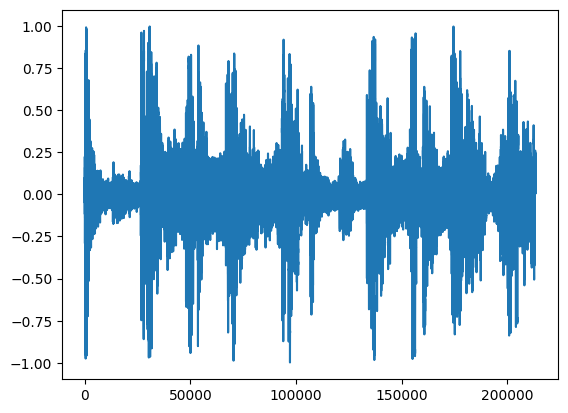

In [8]:
import numpy as np
# Patch deprecated numpy attributes needed by older librosa/pytsmod versions
import sys
if not hasattr(np, 'complex'):
    np.complex = complex
if not hasattr(np, 'float'):
    np.float = float
if not hasattr(np, 'int'):
    np.int = int

import matplotlib.pyplot as plt
import scipy.signal as signal
import IPython.display as ipd
import librosa
import pytsmod
import scipy.io.wavfile as wav
from scipy.io.wavfile import write
import scipy.signal as sig

# use this filename when working locally
filename = '/content/tomsdiner_mono.wav'
# use this filename when working within github
# filename = '../../data/tomsdiner_mono.wav'
srate, tomsdiner_audio = wav.read(filename)

# scale to -1.0/1.0
tomsdiner_audio = tomsdiner_audio.astype(np.float32) / 32767.0

plt.figure()
plt.plot(tomsdiner_audio)

ipd.Audio(tomsdiner_audio, rate=srate)

In [33]:
def save_audio_to_wav(filename, audio, srate=44100):
  """Saves an audio array as a wav file"""
  audio = audio / np.max(np.abs(audio))
  write(filename, srate, audio.astype(np.float32))

In [34]:
# WSOLA Time Stretching:
def wsola_time_stretch(audio, stretch_factor):
  audio_stretched = pytsmod.wsola(audio, stretch_factor)
  return audio_stretched

# stretch factor < 1 = faster, >1 = slower
tomsdiner_slow = wsola_time_stretch(tomsdiner_audio, 1.25)
tomsdiner_fast = wsola_time_stretch(tomsdiner_audio, 0.75)

In [36]:
save_audio_to_wav('audios/tomsdiner_slow_wsola.wav', tomsdiner_slow, srate)
ipd.Audio(tomsdiner_slow, rate=srate)


In [37]:
save_audio_to_wav('audios/tomsdiner_fast_wsola.wav', tomsdiner_fast, srate)
ipd.Audio(tomsdiner_fast, rate=srate)

In [9]:
# Phase Vocoder Time Stretching:

def phase_vocoder_time_stretch(audio, sample_rate, stretch_rate):
  # Convert to frequency domain
  D = librosa.stft(audio, n_fft=1024, hop_length=512)

  # Stretch the audio using the librosa phase_vocoder
  D_stretched = librosa.phase_vocoder(D, rate=stretch_rate, hop_length=512)

  # Reconstruct the audio back to time domain
  audio_stretched = librosa.istft(D_stretched, hop_length=512)

  return audio_stretched

# speed up factor (stretch_rate) >1 is faster, <1 is slower

tomsdiner_slow = phase_vocoder_time_stretch(tomsdiner_audio, srate, 0.25)
tomsdiner_fast = phase_vocoder_time_stretch(tomsdiner_audio, srate, 1.75)


In [ ]:
save_audio_to_wav('audios/tomsdiner_slow_phase_vocoder.wav', tomsdiner_slow, srate)

ipd.Audio(tomsdiner_slow, rate=srate)


In [ ]:
save_audio_to_wav('audios/tomsdiner_fast_phase_vocoder.wav', tomsdiner_fast, srate)
ipd.Audio(tomsdiner_fast, rate=srate)

In [22]:
melody = np.concatenate([tomsdiner_fast[0:4*srate], tomsdiner_fast[0:4*srate]])
slow = tomsdiner_slow[0:4*srate]

# Pad slow with zeros to match melody's length
slow = np.pad(slow, (0, len(melody) - len(slow)))

melody += slow

ipd.Audio(melody, rate=srate) # Interesting...


## Plots
Lets see how well these time stretching techniques preserve the original pitch.

#### Observations
- Both techniques generally preserve pitch as you can see the WSOLA (orange) and phase vocoder (green) closely follow the original. However, WSOLA shows slightly more pitch irregulatities in places where the original signal's voice was undetected (the gaps in the blue line).
- The gaps in the pitch contours are sections where the voiced fundamental frequency were not identifiable by `librosa.pyin` so the time stretched pitch contours in the places where there are gaps in the original audio's pitch contour may or may not be correct.

Both seem to produce good quality audio, and listening to the produced audio I could not hear any obvious distortion, so I believe they both work pretty well.

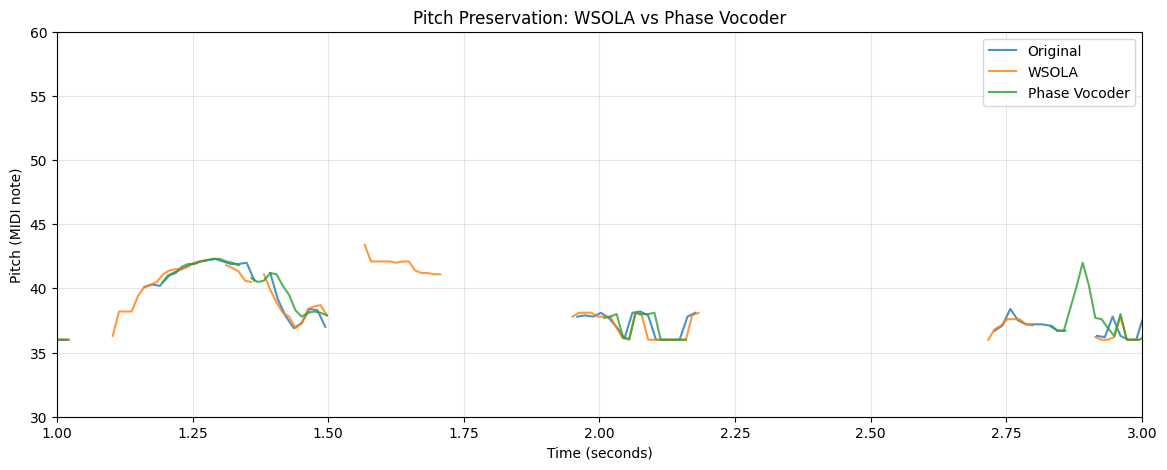

In [31]:
# Use the same stretching factor for both methods
stretch_factor = 1.25

wsola = wsola_time_stretch(tomsdiner_audio, stretch_factor)
pv = phase_vocoder_time_stretch(tomsdiner_audio, srate, 1/stretch_factor)

signals = {
    "Original": tomsdiner_audio,
    "WSOLA": wsola,
    "Phase Vocoder": pv
}

plt.figure(figsize=(14, 5))

for label, audio in signals.items():

    # Estimate fundamental frequency
    f0, _, _ = librosa.pyin(
        audio,
        sr=srate,
        frame_length=2048,
        hop_length=512,
        fmin=librosa.note_to_hz("C2"),
        fmax=librosa.note_to_hz("C7")
    )

    # Convert pitch to MIDI notes
    midi_pitch = librosa.hz_to_midi(f0)

    times = librosa.times_like(f0, sr=srate, hop_length=512)

    # Align original pitch contour with stretched audio
    if label == "Original":
        times = times * stretch_factor

    plt.plot(times, midi_pitch, label=label, alpha=0.8)

plt.xlabel("Time (seconds)")
plt.ylabel("Pitch (MIDI note)")
plt.title("Pitch Preservation: WSOLA vs Phase Vocoder")
plt.legend()
plt.grid(alpha=0.3)


plt.savefig("plots/time_stretch_pitch_comparison.png",
            dpi=300, bbox_inches="tight")
plt.xlim(1,3)
plt.ylim(30, 60)
plt.show()